# Radiation-induced vacancies in halide perovskites
### Abiha — research notebook

**Question:** How reliably can a neural network reproduce proton-induced vacancy-depth profiles for CsPbI₃ and Cs₃Sb₂I₉ at an energy it has never seen?

**Workflow:** Source data → original vacancy profiles → held-out-energy models and baselines → evaluation → physical descriptors and interpretation.

We work with **eight independent material–energy profiles**, not 796 independent irradiation experiments. The workbook is treated as *reported simulation output*; incident ion count, normalization, and whether the values are local or cumulative remain unverified. This notebook does **not** infer device lifetime or radiation tolerance of untested materials.

> **Source-label note:** Two source tabs say `CsPbI9`; the project owner confirmed they mean `CsPbI3`. We retain their original labels in the audit table.

## 1 · Load the workbook

Put the Excel workbook beside this notebook (or in a folder called `upload`). Run cells from top to bottom. In Colab, upload the workbook using the Files sidebar. The same notebook also works in local Jupyter. Required packages: `numpy`, `pandas`, `matplotlib`, `scipy`, `scikit-learn`, `openpyxl`, and `tensorflow`.

In [2]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ENERGIES = [20, 50, 100, 500]
MATERIALS = ["CsPbI3", "Cs3Sb2I9"]
SPECIES = ["vac_Cs", "vac_B", "vac_I"]
SEEDS = [42, 43, 44, 45, 46]

files = sorted(Path(".").rglob("Lumiere Research Data Analaysis*.xlsx"))
if not files:
    raise FileNotFoundError("Upload 'Lumiere Research Data Analaysis.xlsx' first.")
workbook = files[0]
print("Using:", workbook)

Using: Lumiere Research Data Analaysis.xlsx


In [3]:
# Every worksheet has a title row, three header/spacer rows, then numeric data.
tables, audit = [], []
for sheet, raw in pd.read_excel(workbook, sheet_name=None, header=None).items():
    title = str(raw.iat[0, 0]).strip()
    energy_match = re.search(r"(20|50|100|500)\s*keV", title)
    if not energy_match:
        raise ValueError(f"Missing energy in {sheet}: {title}")
    energy = int(energy_match.group(1))
    material = "Cs3Sb2I9" if "Sb" in title else "CsPbI3"

    part = raw.iloc[4:, :4].apply(pd.to_numeric, errors="coerce")
    part = part.loc[part.iloc[:, 0].notna()].copy()
    part.columns = ["depth_angstrom", *SPECIES]
    part["material"], part["energy_keV"] = material, energy
    part["profile_id"] = f"{material}_{energy}keV"
    part["source_sheet"], part["original_title"] = sheet, title
    tables.append(part)
    audit.append([sheet, title, material, energy, len(part), part.depth_angstrom.max()])

df = pd.concat(tables, ignore_index=True)
audit_df = pd.DataFrame(audit, columns=[
    "Sheet", "Original title", "Material", "Energy (keV)", "Rows", "Max depth (Å)"
])

assert len(df) == 796 and df.profile_id.nunique() == 8
assert not df[["depth_angstrom", *SPECIES]].isna().any().any()
assert (df[SPECIES] >= 0).all().all()
assert not df.duplicated(["material", "energy_keV", "depth_angstrom"]).any()

display(audit_df)
df.to_csv("Abiha_clean_profiles.csv", index=False)

,Sheet,Original title,Material,Energy (keV),Rows,Max depth (Å)
0,Sheet1,CsPbI3 in 20 keV,CsPbI3,20,100,10000.00
1,Sheet2,CsPbI9 in 50 keV,CsPbI3,50,100,10000.00
2,Sheet3,CsPbI3 in 100 keV,CsPbI3,100,96,9600.01
3,Sheet4,CsPbI9 in 500 keV,CsPbI3,500,100,10000.00
4,Sheet5,Cs3Sb2I9 in 20 keV,Cs3Sb2I9,20,100,10000.00
5,Sheet6,Cs3Sb2I9 in 50 keV,Cs3Sb2I9,50,100,10000.00
6,Sheet7,Cs3Sb2I9 in 100 keV,Cs3Sb2I9,100,100,10000.00
7,Sheet8,Cs3Sb2I9 in 500 keV,Cs3Sb2I9,500,100,10000.00


### Data quality

The original workbook contains 796 numeric rows across eight material–energy profiles. Seven profiles contain 100 depths; the CsPbI₃ 100 keV profile contains 96 and stops at 9,600.01 Å. Source vacancy values are nonnegative with no missing targets or duplicate depths. These checks establish a usable table but **not** verified vacancy units or irradiation settings.

## 2 · Inspect the original profiles

Plot every material and vacancy species at all four energies. These curves reveal peak shifts, unusual amplitudes, and whether the recorded depth range might cut off a profile.

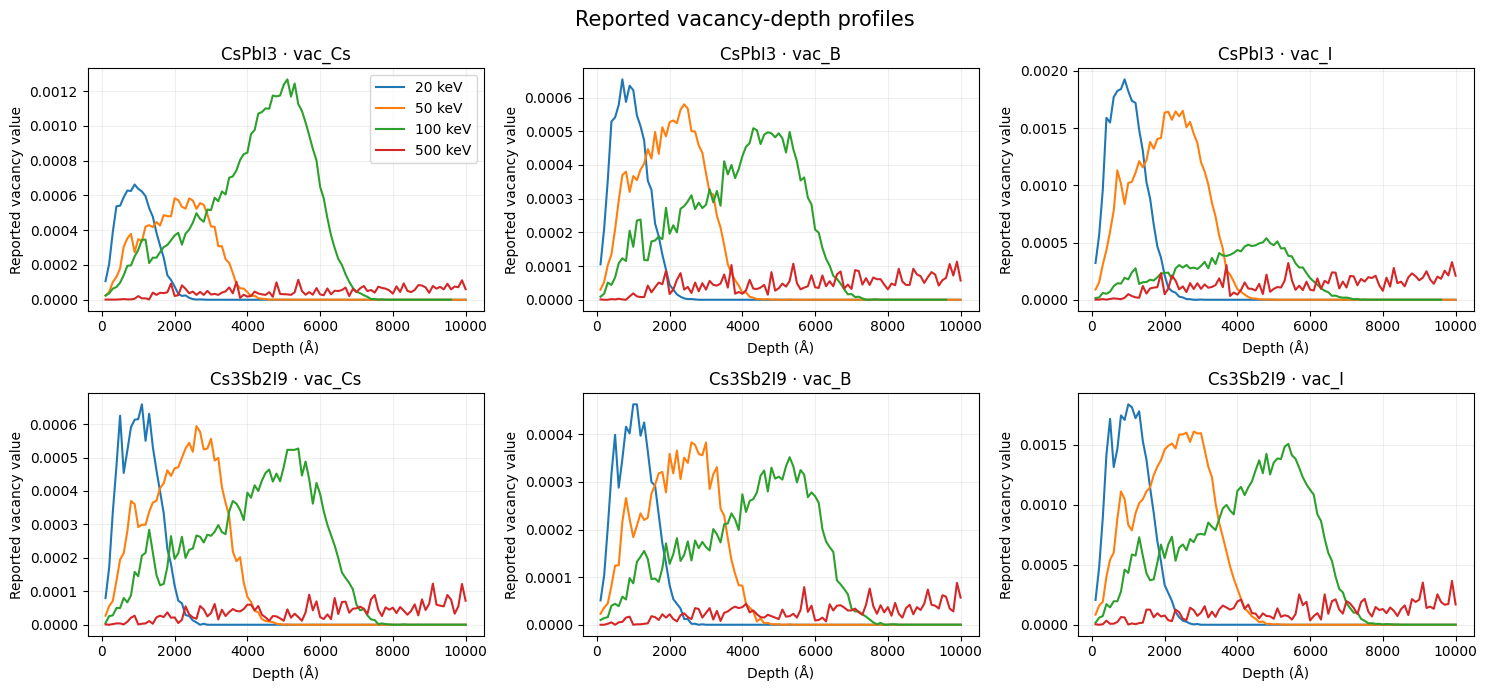

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for i, material in enumerate(MATERIALS):
    for j, species in enumerate(SPECIES):
        ax = axes[i, j]
        for energy in ENERGIES:
            part = df[(df.material == material) & (df.energy_keV == energy)].sort_values("depth_angstrom")
            ax.plot(part.depth_angstrom, part[species], label=f"{energy} keV")
        ax.set(title=f"{material} · {species}", xlabel="Depth (Å)", ylabel="Reported vacancy value")
        ax.grid(alpha=0.2)
axes[0, 0].legend()
plt.suptitle("Reported vacancy-depth profiles", fontsize=15)
plt.tight_layout()
plt.savefig("Figure1_Vacancy_Profiles.png", dpi=300)
plt.show()

**Interpretation:** Vacancy-peak positions generally increase with energy, but peak magnitudes are not always monotonic. Several 500 keV maxima are near the 10,000 Å recorded boundary, making profile truncation a possibility—not an established fact. We cannot infer lower *total* damage from lower recorded amplitudes alone.

## 3 · Define the prediction methods

For each test, hold out **both materials at one energy**. The remaining three energies are used for fitting; one is reserved to select the neural-network training duration, and a final network is refit using all three. Preprocessing is learned exclusively from training data.

- **Original MLP:** energy, depth and material → 64–64–32 hidden neurons → three linear outputs.
- **Improved MLP:** log-energy input and nonnegative Softplus output, with per-species target scaling.
- **Baselines:** zero vacancies, nearest available energy, ordinary linear-energy interpolation/extrapolation, and log-energy interpolation/extrapolation.

The models deliberately share the same hidden-layer sizes. The improvements are *exploratory* because earlier held-out results informed model development; the final test is not an untouched independent assessment.

In [5]:
import tensorflow as tf

def features(frame, improved=False):
    energy = frame.energy_keV.to_numpy(dtype=float)
    if improved:
        energy = np.log10(energy)
    depth = frame.depth_angstrom.to_numpy(dtype=float)
    pb = (frame.material == "CsPbI3").to_numpy(dtype=float)
    sb = (frame.material == "Cs3Sb2I9").to_numpy(dtype=float)
    return np.column_stack([energy, depth, pb, sb])

def make_mlp(improved, seed):
    tf.keras.utils.set_random_seed(seed)
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(4,)),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(3, activation="softplus" if improved else "linear")
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(0.001), loss="mse")
    return model

def train_mlp(train, test, improved, seed):
    validation_energy = sorted(train.energy_keV.unique())[1]
    fit = train[train.energy_keV != validation_energy]
    val = train[train.energy_keV == validation_energy]

    def prepare(fitting, other):
        scaler = StandardScaler().fit(features(fitting, improved))
        x_fit = scaler.transform(features(fitting, improved))
        x_other = scaler.transform(features(other, improved))
        y_fit = fitting[SPECIES].to_numpy()
        if improved:
            scale = np.maximum(np.percentile(y_fit, 95, axis=0), 1e-9)
            offset = np.zeros(3)
        else:
            scale = np.maximum(y_fit.std(axis=0), 1e-9)
            offset = y_fit.mean(axis=0)
        return x_fit, x_other, (y_fit-offset)/scale, scale, offset

    x_fit, x_val, y_fit, scale, offset = prepare(fit, val)
    y_val = (val[SPECIES].to_numpy()-offset)/scale
    trial = make_mlp(improved, seed)
    history = trial.fit(x_fit, y_fit, validation_data=(x_val, y_val),
                        epochs=500, batch_size=32, verbose=0,
                        callbacks=[tf.keras.callbacks.EarlyStopping(
                            monitor="val_loss", patience=35, restore_best_weights=True)])
    best_epoch = int(np.argmin(history.history["val_loss"]) + 1)

    x_train, x_test, y_train, scale, offset = prepare(train, test)
    final = make_mlp(improved, seed)
    final.fit(x_train, y_train, epochs=best_epoch, batch_size=32, verbose=0)
    prediction = final.predict(x_test, verbose=0)*scale + offset
    return prediction, best_epoch

In [6]:
# Each source profile is interpolated over depth only within its recorded range.
def profile_at(train, material, energy, depths):
    p = train[(train.material == material) & (train.energy_keV == energy)].sort_values("depth_angstrom")
    f = interp1d(p.depth_angstrom, p[SPECIES].to_numpy(), axis=0,
                 bounds_error=False, fill_value=np.nan)
    return f(depths)

def make_baselines(train, test):
    output = {name: np.full((len(test), 3), np.nan) for name in
              ["Zero", "Nearest", "Linear energy", "Log energy"]}
    output["Zero"][:] = 0
    for material in MATERIALS:
        idx = np.flatnonzero((test.material == material).to_numpy())
        group = test.iloc[idx]
        energy = int(group.energy_keV.iloc[0])
        z = group.depth_angstrom.to_numpy()
        available = sorted(train[train.material == material].energy_keV.unique())
        nearest = min(available, key=lambda e: abs(e-energy))
        low, high = (available[:2] if energy < available[0]
                     else available[-2:] if energy > available[-1]
                     else (max(e for e in available if e < energy),
                           min(e for e in available if e > energy)))
        a, b = profile_at(train, material, low, z), profile_at(train, material, high, z)
        w = (energy-low)/(high-low)
        wlog = (np.log10(energy)-np.log10(low))/(np.log10(high)-np.log10(low))
        output["Nearest"][idx] = profile_at(train, material, nearest, z)
        output["Linear energy"][idx] = a+w*(b-a)
        output["Log energy"][idx] = a+wlog*(b-a)
    return output

## 4 · Run held-out-energy experiments

This is the only time-consuming cell: two MLP variants × four energies × five seeds, with validation and final refitting. The baseline values are calculated from training profiles and do not require neural-network fitting. Results are stored in simple CSVs.

**Fair scoring:** Some profiles cover less depth. We compare all methods only on depth coordinates supported by *every* interpolation baseline, rather than silently extrapolating depth values.

In [7]:
metrics, predictions = [], []

for energy in ENERGIES:
    train = df[df.energy_keV != energy]
    test = df[df.energy_keV == energy].reset_index(drop=True)
    baselines = make_baselines(train, test)
    actual = test[SPECIES].to_numpy()

    for seed in SEEDS:
        old_pred, old_epoch = train_mlp(train, test, False, seed)
        new_pred, new_epoch = train_mlp(train, test, True, seed)
        methods = {"Original MLP": old_pred, "Improved MLP": new_pred, **baselines}

        detail = test[["material", "energy_keV", "depth_angstrom", "profile_id"]].copy()
        detail["seed"] = seed
        for k, species in enumerate(SPECIES):
            detail[f"{species}_actual"] = actual[:, k]
            for name, values in methods.items():
                detail[f"{species}_{name.replace(' ', '_')}"] = values[:, k]
        predictions.append(detail)

        for material in MATERIALS:
            for k, species in enumerate(SPECIES):
                valid = (test.material == material).to_numpy()
                for values in methods.values():
                    valid &= np.isfinite(values[:, k])
                y = actual[valid, k]
                for name, values in methods.items():
                    yh = values[valid, k]
                    metrics.append({
                        "energy_keV": energy, "material": material, "species": species,
                        "method": name, "seed": seed, "n": len(y),
                        "RMSE": np.sqrt(mean_squared_error(y, yh)),
                        "MAE": mean_absolute_error(y, yh), "R2": r2_score(y, yh),
                        "negative_fraction": np.mean(yh < 0),
                        "epoch": new_epoch if name == "Improved MLP" else old_epoch if name == "Original MLP" else np.nan
                    })
        print(f"Finished {energy} keV, seed {seed}")

metrics_df = pd.DataFrame(metrics)
predictions_df = pd.concat(predictions, ignore_index=True)
metrics_df.to_csv("Abiha_All_Model_Metrics.csv", index=False)
predictions_df.to_csv("Abiha_All_Predictions.csv", index=False)
print("Completed all experiments.")

Finished 20 keV, seed 42
Finished 20 keV, seed 43
Finished 20 keV, seed 44
Finished 20 keV, seed 45
Finished 20 keV, seed 46
Finished 50 keV, seed 42
Finished 50 keV, seed 43
Finished 50 keV, seed 44
Finished 50 keV, seed 45
Finished 50 keV, seed 46
Finished 100 keV, seed 42
Finished 100 keV, seed 43
Finished 100 keV, seed 44
Finished 100 keV, seed 45
Finished 100 keV, seed 46
Finished 500 keV, seed 42
Finished 500 keV, seed 43
Finished 500 keV, seed 44
Finished 500 keV, seed 45
Finished 500 keV, seed 46
Completed all experiments.


## 5 · Compare model accuracy

Use RMSE as the primary comparison metric (lower is better); show MAE and R² as supporting metrics. Very negative R² can occur when the true values have little variance, especially at 500 keV. A model beating linear extrapolation may still perform worse than the zero baseline.

RMSE       MAE            R2
energy_keV method                                         
20         Improved MLP   0.000290  0.000235      0.035631
           Linear energy  0.000490  0.000322     -1.757292
           Log energy     0.000748  0.000502     -5.981863
           Nearest        0.000349  0.000199     -0.363495
           Original MLP   0.000293  0.000239     -0.038428
           Zero           0.000329  0.000138     -0.210843
50         Improved MLP   0.000315  0.000278     -0.009999
           Linear energy  0.000306  0.000201      0.039292
           Log energy     0.000322  0.000216     -0.155203
           Nearest        0.000349  0.000199     -0.216002
           Original MLP   0.000273  0.000213      0.265644
           Zero           0.000390  0.000227     -0.511763
100        Improved MLP   0.000316  0.000214     -0.720583
           Linear energy  0.000402  0.000281     -2.284626
           Log energy     0.000366  0.000251     -1.454811
           Nearest        0.000426  0.000301     -2.899262
           Original MLP   0.000366  0.000256     -1.406132
           Zero           0.000378  0.000279     -1.223207
500        Improved MLP   0.000334  0.000263   -300.630857
           Linear energy  0.003616  0.002532 -11215.898761
           Log energy     0.001215  0.000832  -1389.073220
           Nearest        0.000343  0.000268   -131.775260
           Original MLP   0.001146  0.001105  -1149.938672
           Zero           0.000076  0.000065     -2.683113

Lowest-RMSE method per material/energy/species:


,energy_keV,material,species,method,RMSE
4,20,Cs3Sb2I9,vac_B,Original MLP,0.000124
6,20,Cs3Sb2I9,vac_Cs,Improved MLP,0.000183
12,20,Cs3Sb2I9,vac_I,Improved MLP,0.000512
18,20,CsPbI3,vac_B,Improved MLP,0.000177
24,20,CsPbI3,vac_Cs,Improved MLP,0.000196
34,20,CsPbI3,vac_I,Original MLP,0.000481
40,50,Cs3Sb2I9,vac_B,Original MLP,0.000112
46,50,Cs3Sb2I9,vac_Cs,Original MLP,0.000166
52,50,Cs3Sb2I9,vac_I,Original MLP,0.000482
58,50,CsPbI3,vac_B,Original MLP,0.000170


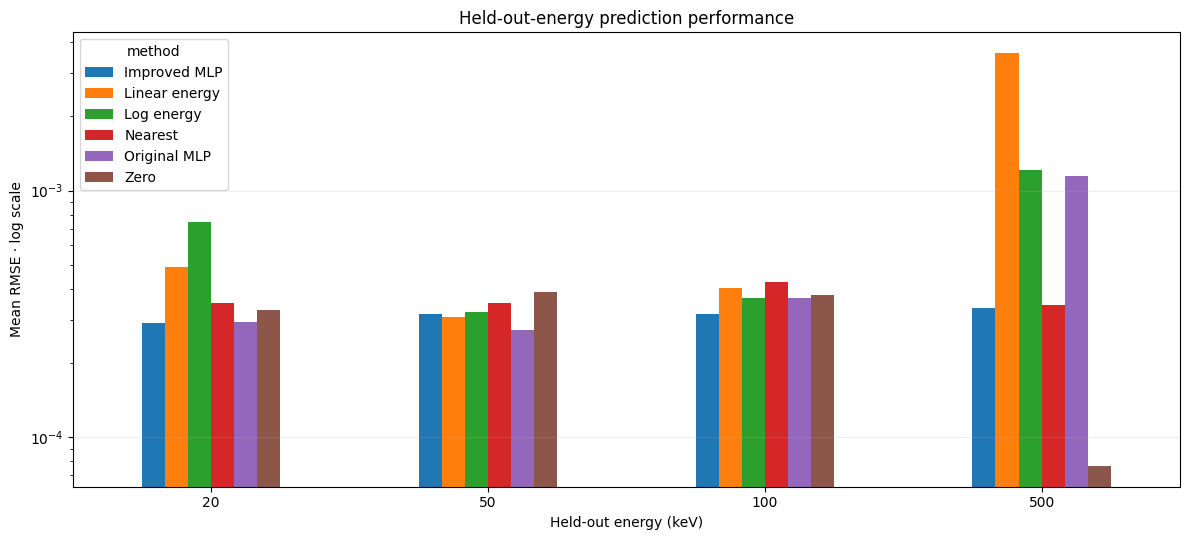

In [8]:
summary = metrics_df.groupby(["energy_keV", "method"])[["RMSE", "MAE", "R2"]].mean()
display(summary.round(7))

winners = (metrics_df.groupby(["energy_keV", "material", "species", "method"])
           .RMSE.mean().reset_index())
winners = winners.loc[winners.groupby(["energy_keV", "material", "species"]).RMSE.idxmin()]
print("Lowest-RMSE method per material/energy/species:")
display(winners.sort_values(["energy_keV", "material", "species"]))

ax = summary.RMSE.unstack().plot.bar(figsize=(12, 5.5), logy=True)
ax.set(xlabel="Held-out energy (keV)", ylabel="Mean RMSE · log scale",
       title="Held-out-energy prediction performance")
ax.grid(axis="y", alpha=0.2)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("Figure2_Model_Comparison.png", dpi=300)
plt.show()

**Interpretation:** Earlier exploratory runs showed the improved MLP winning many 20 and 100 keV comparisons, linear interpolation often winning at 50 keV, and zero prediction frequently winning at 500 keV. Treat the **table generated above** as authoritative for this clean rerun. Don't describe one MLP as generally accurate without comparing it against *all* baselines.

## 6 · Analyze peak positions and magnitudes

These are descriptive statistics of reported profiles, not total physical defect counts. We deliberately avoid integrating them until the source's local-versus-cumulative definition and normalization are verified.

,material,energy_keV,species,peak_value,peak_depth_angstrom,mean_value,last_depth_angstrom
0,Cs3Sb2I9,20,vac_Cs,0.000659,1100.01,0.000088,10000.00
1,Cs3Sb2I9,20,vac_B,0.000463,1000.01,0.000060,10000.00
2,Cs3Sb2I9,20,vac_I,0.001839,1000.01,0.000254,10000.00
3,Cs3Sb2I9,50,vac_Cs,0.000594,2600.01,0.000143,10000.00
4,Cs3Sb2I9,50,vac_B,0.000383,2600.01,0.000097,10000.00
5,Cs3Sb2I9,50,vac_I,0.001612,2800.01,0.000419,10000.00
6,Cs3Sb2I9,100,vac_Cs,0.000527,5400.01,0.000194,10000.00
7,Cs3Sb2I9,100,vac_B,0.000352,5300.01,0.000128,10000.00
8,Cs3Sb2I9,100,vac_I,0.001509,5400.01,0.000556,10000.00
9,Cs3Sb2I9,500,vac_Cs,0.000123,9100.01,0.000039,10000.00


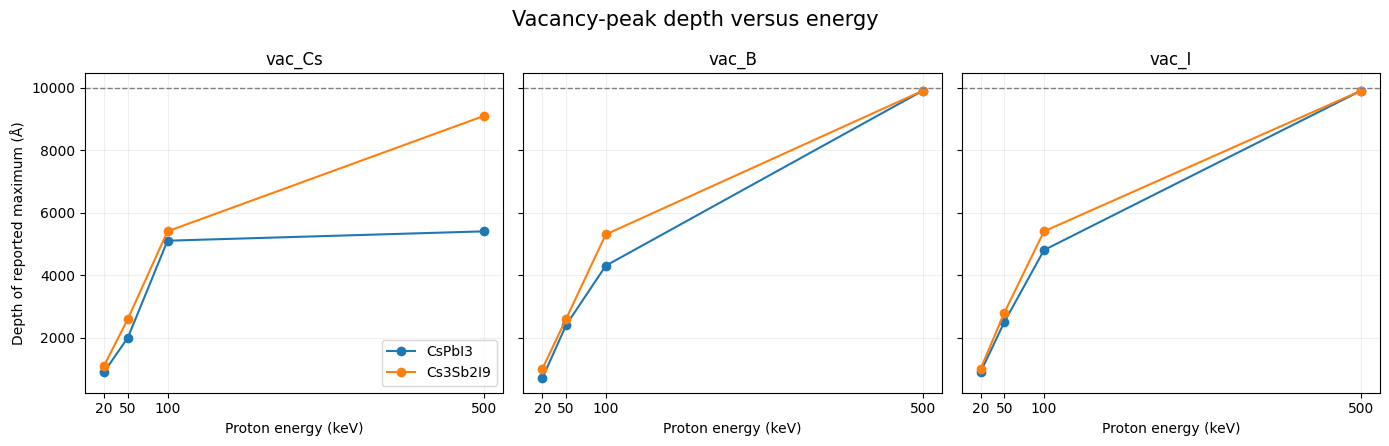

In [9]:
rows = []
for (material, energy), part in df.groupby(["material", "energy_keV"]):
    p = part.sort_values("depth_angstrom")
    for species in SPECIES:
        peak = p.loc[p[species].idxmax()]
        rows.append({"material": material, "energy_keV": energy, "species": species,
                     "peak_value": peak[species], "peak_depth_angstrom": peak.depth_angstrom,
                     "mean_value": p[species].mean(), "last_depth_angstrom": p.depth_angstrom.max()})
profile_summary = pd.DataFrame(rows)
display(profile_summary.round(7))
profile_summary.to_csv("Abiha_Profile_Descriptors.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True)
for ax, species in zip(axes, SPECIES):
    for material in MATERIALS:
        part = profile_summary[(profile_summary.material == material) &
                               (profile_summary.species == species)].sort_values("energy_keV")
        ax.plot(part.energy_keV, part.peak_depth_angstrom, "o-", label=material)
    ax.axhline(10000, ls="--", color="gray", lw=1)
    ax.set(xlabel="Proton energy (keV)", title=species)
    ax.set_xticks(ENERGIES)
    ax.grid(alpha=0.2)
axes[0].set_ylabel("Depth of reported maximum (Å)")
axes[0].legend()
plt.suptitle("Vacancy-peak depth versus energy", fontsize=15)
plt.tight_layout()
plt.savefig("Figure3_Peak_Depths.png", dpi=300)
plt.show()

**Interpretation:** Iodine-vacancy peaks generally migrate deeper with increasing energy. For both materials the reported I-vacancy maximum at 500 keV is near **9,900 Å**, close to the **10,000 Å** last recorded depth. Possible missing downstream damage must be investigated before comparing total damage. The CsPbI₃ 100 keV Cs-vacancy peak is unusually high relative to the other energies and should be verified in the source simulation.

## 7 · Inspect the most difficult extrapolation (500 keV)

This figure uses seed 42 as an illustrative run. The tables above summarize five seeds. Compare *shape and magnitude*, not just aggregate metrics.

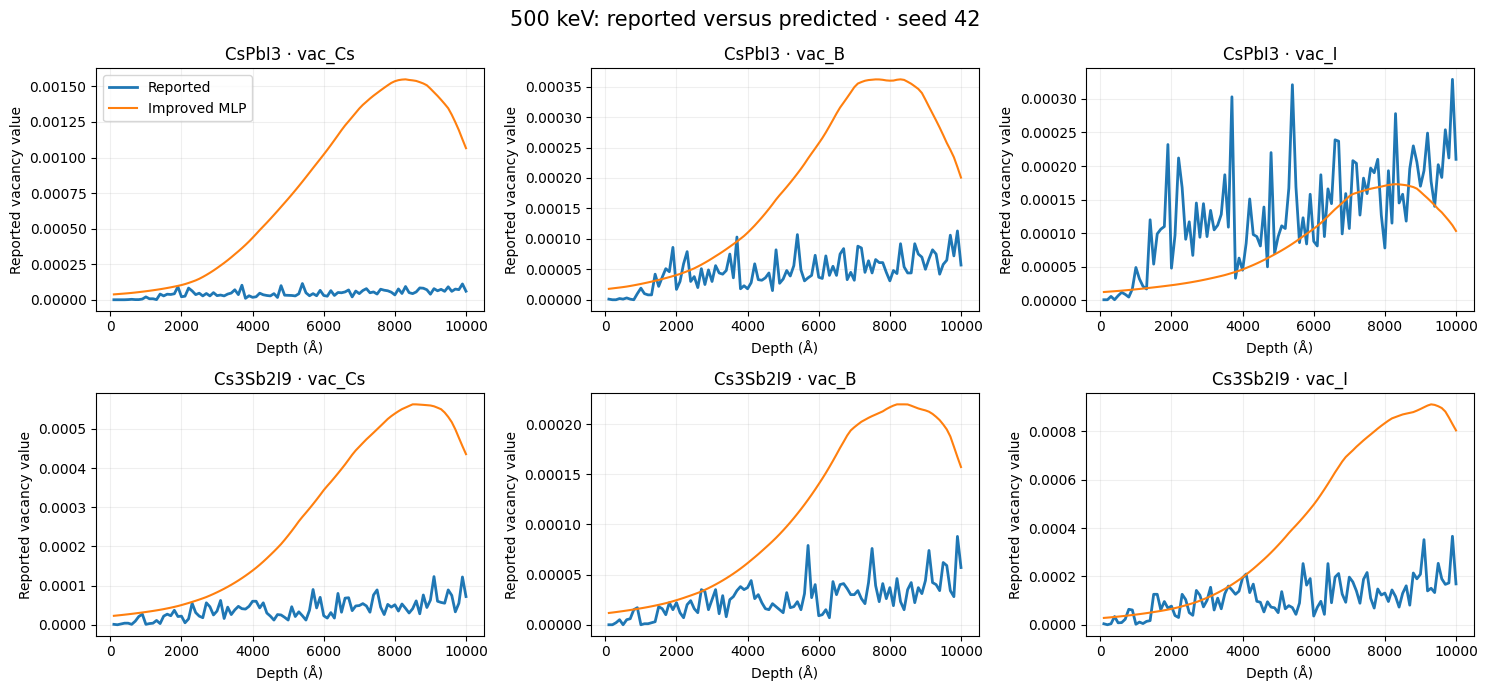

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for i, material in enumerate(MATERIALS):
    p = predictions_df[(predictions_df.material == material) &
                       (predictions_df.energy_keV == 500) &
                       (predictions_df.seed == 42)].sort_values("depth_angstrom")
    for j, species in enumerate(SPECIES):
        ax = axes[i, j]
        ax.plot(p.depth_angstrom, p[f"{species}_actual"], label="Reported", lw=2)
        ax.plot(p.depth_angstrom, p[f"{species}_Improved_MLP"], label="Improved MLP")
        ax.set(xlabel="Depth (Å)", ylabel="Reported vacancy value", title=f"{material} · {species}")
        ax.grid(alpha=0.2)
axes[0, 0].legend()
plt.suptitle("500 keV: reported versus predicted · seed 42", fontsize=15)
plt.tight_layout()
plt.savefig("Figure4_500keV_Predictions.png", dpi=300)
plt.show()

## 8 · Main findings and limitations

1. **The evaluation design matters.** Holding out complete energies is more defensible than randomly splitting correlated depth rows.
2. **Neural networks have mixed predictive value.** A nonnegative MLP can improve some scores, yet trivial or interpolation baselines can perform better at other energies.
3. **High-energy extrapolation remains uncertain.** At 500 keV, small source vacancy values and peaks near the recorded depth boundary make errors and interpretations particularly sensitive.
4. **Damage shifts with depth.** Peak migration is a useful descriptive result, but it is not evidence of superior device radiation hardness.
5. **The evidence is limited.** Only eight independent profiles exist; ion fluence/count, normalization, source settings, and full 500 keV depth support require verification. Repeated seeds are not a substitute for more independent simulations.

### Next research direction

Proceed to separate, phase-specific electronic and stability screening of lead-free candidate materials using independent databases and literature. **Do not use this two-material MLP to infer radiation damage in unseen chemical formulas.**

**Files generated:** cleaned profile CSV, all-model metrics/predictions CSVs, peak-descriptor CSV, and four 300-dpi PNG figures. The original Excel workbook is never modified.